In [1]:

!pip install -q opencv-python-headless scikit-image


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
# Operating system and file path utilities
import os
import hashlib
import sys
import time
import zipfile
import random
from pathlib import Path
from collections import Counter

# Core scientific computation and data manipulation
import numpy as np
import pandas as pd

# Image processing and manipulation
import cv2
from PIL import Image

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Handcrafted feature extraction from scikit-image
from skimage.feature import (
    local_binary_pattern,
    graycomatrix,
    graycoprops,
    hog
)

# Machine learning pipelines, algorithms, and evaluation metrics from scikit-learn
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    log_loss
)
import joblib

# Display utility fallback
try:
    from IPython.display import display
except ImportError:
    display = print

# Configure plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
sns.set_palette("Set2")

# Set global random seeds for full reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("✅ All required libraries imported successfully!")
print(f"   • Python:       {sys.version.split()[0]}")
print(f"   • NumPy:        {np.__version__}")
print(f"   • Pandas:       {pd.__version__}")
print(f"   • OpenCV:       {cv2.__version__}")
print(f"   • Scikit-Learn: {sklearn.__version__}")



✅ All required libraries imported successfully!
   • Python:       3.14.9
   • NumPy:        2.5.4
   • Pandas:       3.1.1
   • OpenCV:       5.0.0
   • Scikit-Learn: 1.9.1


In [3]:
# -----------------------------------------------------------------------------
# 1. Environment Detection & Path Resolution
# -----------------------------------------------------------------------------
IN_COLAB = "google.colab" in sys.modules

# Set this explicitly when your dataset is stored in a custom location.
# In Colab, upload plant-dataset.zip to /content or set this to your extracted folder.
# Examples: Path("/content/plant_disease_data/PlantVillage") or
# Path("/content/drive/MyDrive/PlantVillage")
DATASET_DIR_OVERRIDE = None

# Common locations in this repository, Colab, and Google Drive.
POSSIBLE_DATA_DIRS = [
    Path("data/raw/plantvillage/PlantVillage"),
    Path("data/raw/PlantVillage"),
    Path("data/raw/plantvillage"),
    Path("/content/plant_disease_data/PlantVillage"),
    Path("/content/plant_disease_data"),
    Path("/content/drive/MyDrive/PlantVillage"),
    Path("/content/drive/MyDrive/plant-disease-ml/data/raw/plantvillage/PlantVillage"),
    Path("/content/PlantVillage"),
    Path("/content/drive/MyDrive/PlantVillage"),
    Path("/content/drive/MyDrive/plant-disease-ml/data/raw/plantvillage/PlantVillage"),
    Path("./PlantVillage"),
]
if DATASET_DIR_OVERRIDE is not None:
    POSSIBLE_DATA_DIRS.insert(0, Path(DATASET_DIR_OVERRIDE))

POSSIBLE_ZIP_PATHS = [
    Path("plant-dataset.zip"),
    Path("archive.zip"),
    Path("/content/plant-dataset.zip"),
    Path("/content/archive.zip"),
    Path("/content/drive/MyDrive/plant-dataset.zip"),
    Path("/content/drive/MyDrive/archive.zip"),
    Path("data/plant-dataset.zip"),
]

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
def contains_class_images(directory):
    """Return True when this folder contains images in class subfolders."""
    return directory.is_dir() and any(
        item.is_file() and item.suffix.lower() in IMAGE_SUFFIXES
        for item in directory.rglob("*")
    )

DATASET_DIR = None
for directory in POSSIBLE_DATA_DIRS:
    if contains_class_images(directory):
        DATASET_DIR = directory
        print(f"📁 Found dataset images under: {DATASET_DIR}")
        break

# If no extracted dataset was found, extract a known ZIP archive.
if DATASET_DIR is None:
    for zip_candidate in POSSIBLE_ZIP_PATHS:
        if zip_candidate.is_file():
            print(f"📦 Found ZIP archive at: {zip_candidate}. Extracting...")
            extract_target = Path("/content/plant_disease_data" if IN_COLAB else "data/raw/PlantVillage")
            extract_target.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(zip_candidate, "r") as archive:
                archive.extractall(extract_target)
            # ZIP files may contain one or more enclosing folders; locate the image root.
            matches = [p for p in [extract_target, *extract_target.iterdir()] if contains_class_images(p)]
            if matches:
                DATASET_DIR = matches[0]
                print(f"✅ Extracted dataset images to: {DATASET_DIR}")
                break

if DATASET_DIR is None:
    searched = "\n".join(f"  - {path}" for path in POSSIBLE_DATA_DIRS + POSSIBLE_ZIP_PATHS)
    raise FileNotFoundError(
        "PlantVillage images were not found. In Colab, mount Google Drive or upload/extract "
        "the dataset, then set DATASET_DIR_OVERRIDE to its folder. Searched locations:\n" + searched
    )

print(f"\n✅ Using dataset folder: {DATASET_DIR.resolve()}")

# -----------------------------------------------------------------------------
# 2. Output Directories
# -----------------------------------------------------------------------------
PROJECT_ROOT = Path(".") if not IN_COLAB else Path("/content")
FEATURE_DIR = PROJECT_ROOT / "plant_features"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

for folder in [FEATURE_DIR, MODEL_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Cache file paths for extracted features
X_TRAIN_FILE = FEATURE_DIR / "X_train_features.npy"
X_TEST_FILE = FEATURE_DIR / "X_test_features.npy"

# -----------------------------------------------------------------------------
# 3. Hyperparameters & Pipeline Specifications
# -----------------------------------------------------------------------------
IMAGE_SIZE = (128, 128)
RANDOM_STATE = 42
TEST_SIZE = 0.20
BATCH_SIZE = 64

# Feature extraction parameters
COLOR_HIST_BINS = 8
LBP_RADIUS = 3
LBP_POINTS = 24
GLCM_DISTANCES = [1, 3]
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
GLCM_LEVELS = 32
HOG_ORIENTATIONS = 9
HOG_PIXELS_PER_CELL = (8, 8)
HOG_CELLS_PER_BLOCK = (2, 2)

# Expected feature vector dimension:
# RGB (24) + HSV (24) + LBP (26) + GLCM (48) + HOG (8,100) = 8,222
FEATURE_DIM = 8222

print("\n⚙️ Project Configuration Summary:")
print(f"   • Running in Colab:   {IN_COLAB}")
print(f"   • Dataset Directory:  {DATASET_DIR}")
print(f"   • Target Image Size:  {IMAGE_SIZE}")
print(f"   • Train / Test Split: {int((1 - TEST_SIZE)*100)}% / {int(TEST_SIZE*100)}%")
print(f"   • Feature Dimensions: {FEATURE_DIM:,} features")
print(f"   • Batch Size:         {BATCH_SIZE}")


📁 Found dataset images under: data/raw/PlantVillage

✅ Using dataset folder: /home/rosa/Pictures/data/raw/PlantVillage

⚙️ Project Configuration Summary:
   • Running in Colab:   False
   • Dataset Directory:  data/raw/PlantVillage
   • Target Image Size:  (128, 128)
   • Train / Test Split: 80% / 20%
   • Feature Dimensions: 8,222 features
   • Batch Size:         64


In [4]:
# Supported image file extensions
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Scan all subdirectories recursively
records = []
for file_path in sorted(DATASET_DIR.rglob("*")):
    if file_path.is_file() and file_path.suffix.lower() in IMAGE_EXTENSIONS:
        class_name = file_path.parent.name
        # Skip top-level parent directory if misidentified as a class
        if class_name in ["PlantVillage", "raw", "data", "plant_disease_data", "PlantVillage-Dataset-master"]:
            continue
        records.append({
            "path": str(file_path),
            "class": class_name,
            "filename": file_path.name
        })

if not records:
    raise ValueError(
        f"No supported images were found under {DATASET_DIR}. "
        "Set DATASET_DIR_OVERRIDE to the folder containing the class subfolders."
    )

df_images = pd.DataFrame(records)

# Automatically filter out classes with fewer than 2 images to satisfy stratified splitting
class_counts = df_images["class"].value_counts()
classes_with_too_few_images = class_counts[class_counts < 2]

if not classes_with_too_few_images.empty:
    print(f"⚠️ Excluding {len(classes_with_too_few_images)} class(es) with only 1 image to allow stratified split:")
    for cls_name in classes_with_too_few_images.index:
        print(f"   - {cls_name}")
    # Filter the dataframe to keep classes with 2 or more images
    df_images = df_images[~df_images["class"].isin(classes_with_too_few_images.index)].copy()

# Extract plant species as an auxiliary attribute (e.g. 'Tomato', 'Pepper', 'Potato')
df_images["species"] = df_images["class"].apply(
    lambda x: x.split("___")[0].split("_")[0] if "___" in x or "_" in x else "Unknown"
)

print(f"\n✅ Dataset scanned and filtered successfully!")
print(f"   • Total Images:  {len(df_images):,}")
print(f"   • Total Classes: {df_images['class'].nunique()}")
print(f"   • Plant Species: {df_images['species'].unique().tolist()}")

# Preview top records
display(df_images.head())



✅ Dataset scanned and filtered successfully!
   • Total Images:  41,276
   • Total Classes: 15
   • Plant Species: ['Pepper', 'Potato', 'Tomato']


,path,class,filename,species
0,data/raw/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,0022d6b7-d47c-4ee2-ae9a-392a53f48647___JR_B.Sp...,Pepper
1,data/raw/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,006adb74-934f-448f-a14f-62181742127b___JR_B.Sp...,Pepper
2,data/raw/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,00f2e69a-1e56-412d-8a79-fdce794a17e4___JR_B.Sp...,Pepper
3,data/raw/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,01613cd0-d3cd-4e96-945c-a312002037bf___JR_B.Sp...,Pepper
4,data/raw/PlantVillage/PlantVillage/Pepper__bel...,Pepper__bell___Bacterial_spot,0169b9ac-07b9-4be1-8b85-da94481f05a4___NREC_B....,Pepper


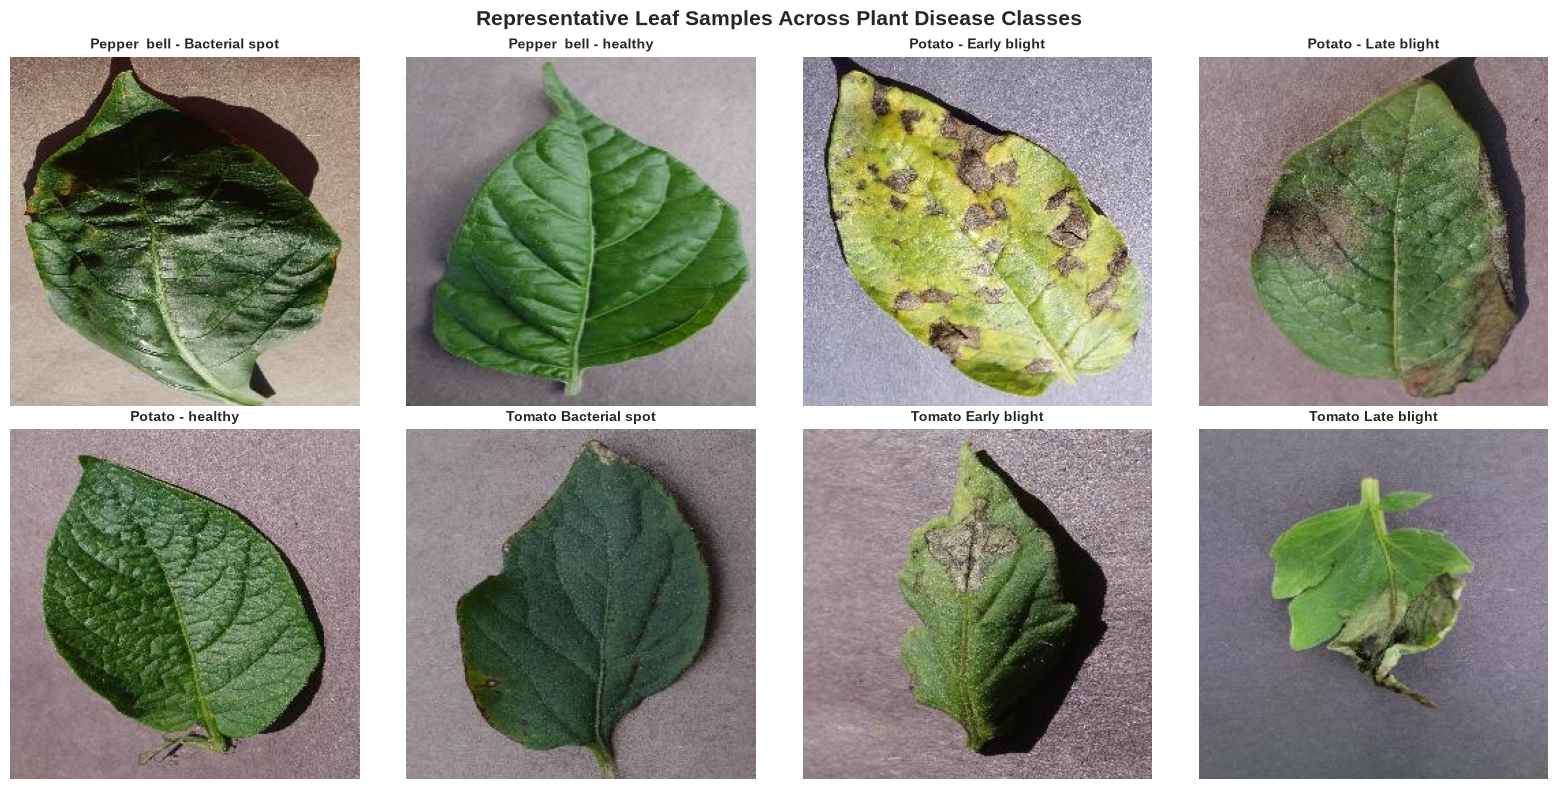

In [5]:
# -----------------------------------------------------------------------------
# 2. Visual Inspection: Sample Leaf Images
# -----------------------------------------------------------------------------
NUM_CLASSES_DISPLAY = min(8, df_images["class"].nunique())
sample_classes = df_images["class"].unique()[:NUM_CLASSES_DISPLAY]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, class_name in enumerate(sample_classes):
    sample_row = df_images[df_images["class"] == class_name].sample(1, random_state=SEED).iloc[0]
    sample_img = Image.open(sample_row["path"]).convert("RGB")

    axes[idx].imshow(sample_img)
    clean_title = class_name.replace("___", " - ").replace("_", " ")
    axes[idx].set_title(clean_title, fontsize=10, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("Representative Leaf Samples Across Plant Disease Classes", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


🔍 Integrity Audit (Sample of 1000 images):
   • Corrupted Images:      0
   • Unique Dimensions:     [{'width': 256, 'height': 256}]
   • Formats Detected:      {'JPEG': 1000}
   • Color Modes Detected:  {'RGB': 1000}


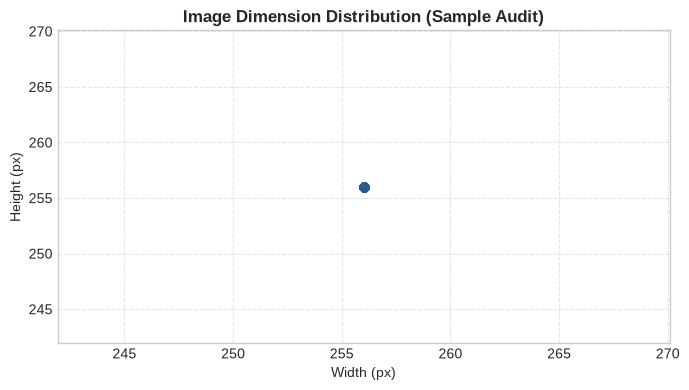

In [6]:
# -----------------------------------------------------------------------------
# 3. Image Dimension & Integrity Audit
# -----------------------------------------------------------------------------
# Audit a stratified sample of up to 1,000 images for fast, representative verification
sample_audit_paths = df_images["path"].sample(min(1000, len(df_images)), random_state=SEED)

audit_info = []
corrupted = []

for img_p in sample_audit_paths:
    try:
        with Image.open(img_p) as img:
            audit_info.append({
                "width": img.width,
                "height": img.height,
                "format": img.format,
                "mode": img.mode
            })
    except Exception:
        corrupted.append(img_p)

df_audit = pd.DataFrame(audit_info)

print(f"🔍 Integrity Audit (Sample of {len(sample_audit_paths)} images):")
print(f"   • Corrupted Images:      {len(corrupted)}")
print(f"   • Unique Dimensions:     {df_audit[['width', 'height']].drop_duplicates().to_dict('records')}")
print(f"   • Formats Detected:      {df_audit['format'].value_counts().to_dict()}")
print(f"   • Color Modes Detected:  {df_audit['mode'].value_counts().to_dict()}")

# Scatter plot of dimensions
plt.figure(figsize=(7, 4))
plt.scatter(df_audit["width"], df_audit["height"], alpha=0.4, color="#2b5c8f")
plt.title("Image Dimension Distribution (Sample Audit)", fontsize=12, fontweight="bold")
plt.xlabel("Width (px)")
plt.ylabel("Height (px)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


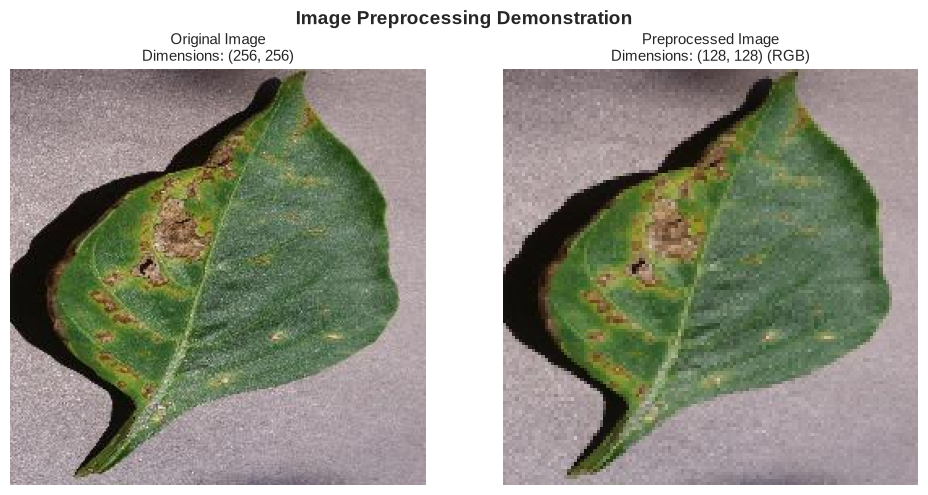

Pixel Value Range: [0, 214] | Data Type: uint8


In [7]:
def preprocess_image(image_path, image_size=IMAGE_SIZE):
    """
    Load an image from disk, convert BGR to RGB, and resize to fixed dimensions.
    """
    image = cv2.imread(str(image_path))
    if image is None:
        return None

    # Convert OpenCV BGR format to standard RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize with INTER_AREA interpolation for high-fidelity downsampling
    image = cv2.resize(image, image_size, interpolation=cv2.INTER_AREA)
    return image

# Demonstrate preprocessing on a sample leaf
sample_path = df_images.iloc[0]["path"]
sample_original = Image.open(sample_path).convert("RGB")
sample_processed = preprocess_image(sample_path, IMAGE_SIZE)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(sample_original)
axes[0].set_title(f"Original Image\nDimensions: {sample_original.size}", fontsize=11)
axes[0].axis("off")

axes[1].imshow(sample_processed)
axes[1].set_title(f"Preprocessed Image\nDimensions: {sample_processed.shape[:2]} (RGB)", fontsize=11)
axes[1].axis("off")

plt.suptitle("Image Preprocessing Demonstration", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Pixel Value Range: [{sample_processed.min()}, {sample_processed.max()}] | Data Type: {sample_processed.dtype}")


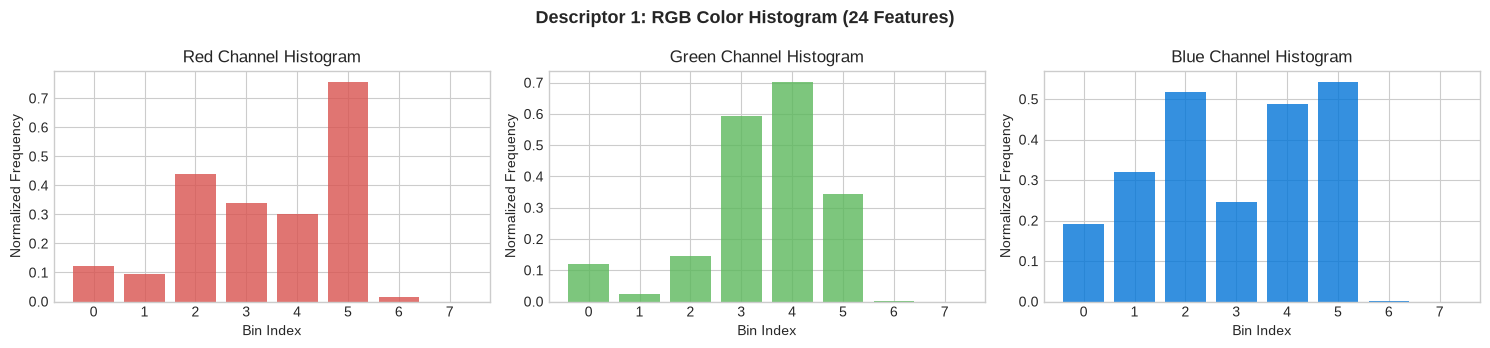

RGB feature vector shape: (24,)


In [8]:
# -----------------------------------------------------------------------------
# Descriptor 1: RGB Color Histogram (24 Features)
# -----------------------------------------------------------------------------
def extract_rgb_histogram(image, bins=COLOR_HIST_BINS):
    """Extract an 8-bin normalized histogram per RGB channel (24 features)."""
    features = []
    for channel in range(3):
        hist = cv2.calcHist([image], [channel], None, [bins], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        features.extend(hist)
    return np.array(features, dtype=np.float32)

rgb_feats = extract_rgb_histogram(sample_processed)

# Visualize RGB Histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
colors = ["#d9534f", "#5cb85c", "#0275d8"]
channel_names = ["Red", "Green", "Blue"]

for i, (ax, col, name) in enumerate(zip(axes, colors, channel_names)):
    ax.bar(range(COLOR_HIST_BINS), rgb_feats[i*8:(i+1)*8], color=col, alpha=0.8)
    ax.set_title(f"{name} Channel Histogram")
    ax.set_xlabel("Bin Index")
    ax.set_ylabel("Normalized Frequency")

plt.suptitle("Descriptor 1: RGB Color Histogram (24 Features)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"RGB feature vector shape: {rgb_feats.shape}")


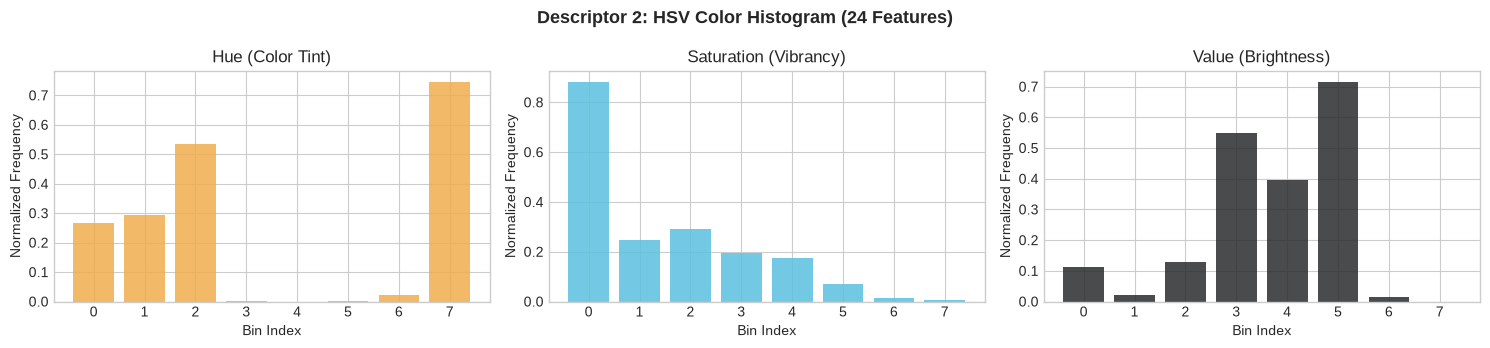

HSV feature vector shape: (24,)


In [9]:
# -----------------------------------------------------------------------------
# Descriptor 2: HSV Color Histogram (24 Features)
# -----------------------------------------------------------------------------
def extract_hsv_histogram(image, bins=COLOR_HIST_BINS):
    """Extract an 8-bin normalized histogram per HSV channel (24 features)."""
    hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    features = []
    # OpenCV HSV ranges: H in [0, 180], S in [0, 256], V in [0, 256]
    ranges = [[0, 180], [0, 256], [0, 256]]

    for ch, val_range in enumerate(ranges):
        hist = cv2.calcHist([hsv_image], [ch], None, [bins], val_range)
        hist = cv2.normalize(hist, hist).flatten()
        features.extend(hist)
    return np.array(features, dtype=np.float32)

hsv_feats = extract_hsv_histogram(sample_processed)

# Visualize HSV Histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
hsv_names = ["Hue (Color Tint)", "Saturation (Vibrancy)", "Value (Brightness)"]
palette_hsv = ["#f0ad4e", "#5bc0de", "#292b2c"]

for i, (ax, col, name) in enumerate(zip(axes, palette_hsv, hsv_names)):
    ax.bar(range(COLOR_HIST_BINS), hsv_feats[i*8:(i+1)*8], color=col, alpha=0.85)
    ax.set_title(f"{name}")
    ax.set_xlabel("Bin Index")
    ax.set_ylabel("Normalized Frequency")

plt.suptitle("Descriptor 2: HSV Color Histogram (24 Features)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"HSV feature vector shape: {hsv_feats.shape}")


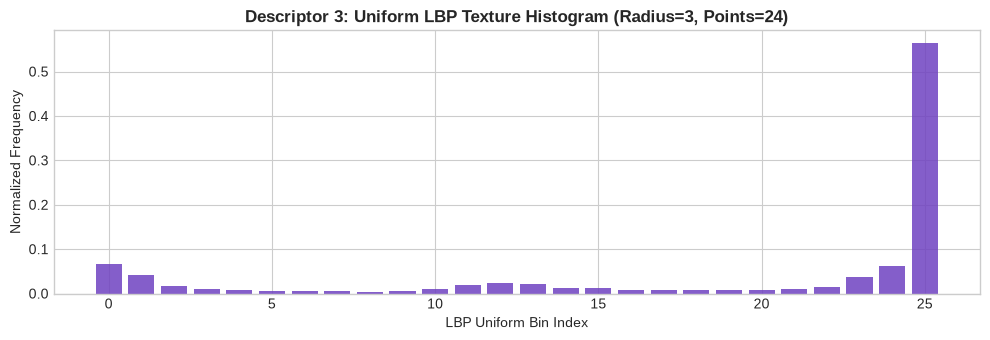

LBP feature vector shape: (26,)


In [10]:
# -----------------------------------------------------------------------------
# Descriptor 3: Uniform Local Binary Patterns (LBP) (26 Features)
# -----------------------------------------------------------------------------
def extract_lbp_features(image, radius=LBP_RADIUS, points=LBP_POINTS):
    """Extract uniform Local Binary Patterns texture histogram (P + 2 = 26 bins)."""
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(gray, points, radius, method="uniform")
    num_bins = points + 2
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, num_bins + 1), range=(0, num_bins))
    hist = hist.astype(np.float32)
    hist /= (hist.sum() + 1e-7)
    return hist

lbp_feats = extract_lbp_features(sample_processed)

# Visualize LBP Histogram
plt.figure(figsize=(10, 3.5))
plt.bar(range(len(lbp_feats)), lbp_feats, color="#6f42c1", alpha=0.85)
plt.title(f"Descriptor 3: Uniform LBP Texture Histogram (Radius={LBP_RADIUS}, Points={LBP_POINTS})", fontsize=12, fontweight="bold")
plt.xlabel("LBP Uniform Bin Index")
plt.ylabel("Normalized Frequency")
plt.tight_layout()
plt.show()
print(f"LBP feature vector shape: {lbp_feats.shape}")


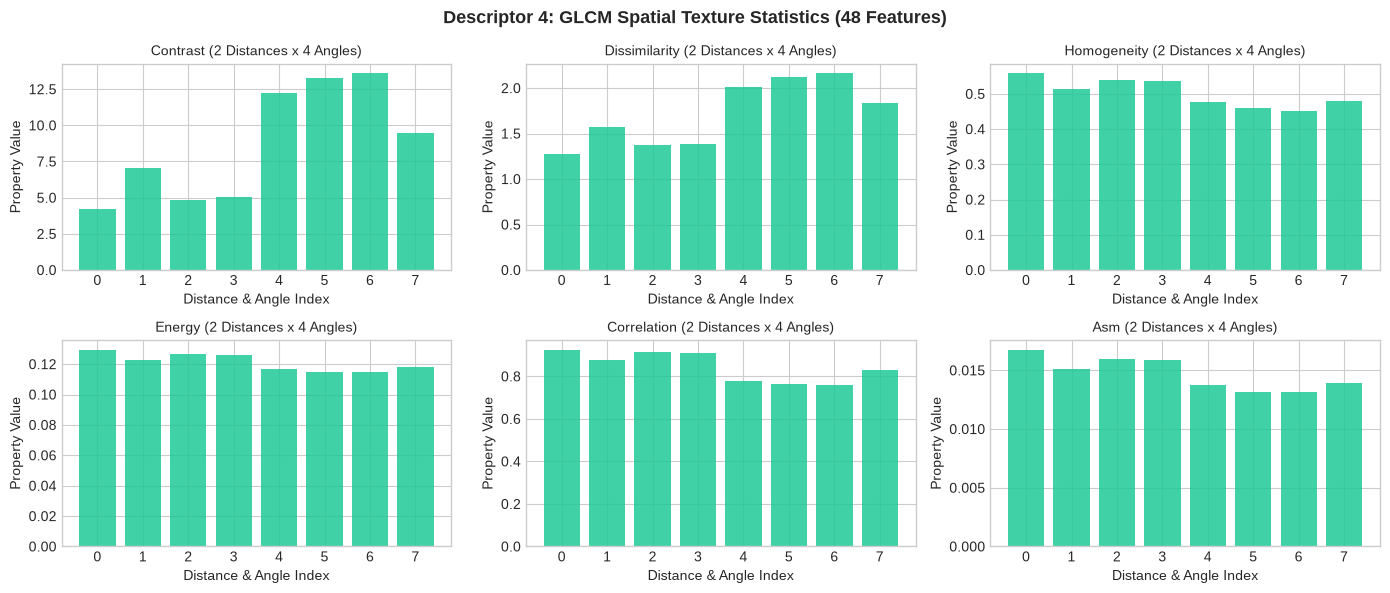

GLCM feature vector shape: (48,)


In [11]:
# -----------------------------------------------------------------------------
# Descriptor 4: Gray-Level Co-occurrence Matrix (GLCM) (48 Features)
# -----------------------------------------------------------------------------
def extract_glcm_features(image):
    """
    Extract statistical GLCM texture properties:
    6 properties x 2 distances x 4 angles = 48 numerical features.
    """
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    # Quantize grayscale image to 32 levels to capture stable spatial co-occurrence
    gray_quantized = (gray // 8).astype(np.uint8)

    glcm = graycomatrix(
        gray_quantized,
        distances=GLCM_DISTANCES,
        angles=GLCM_ANGLES,
        levels=GLCM_LEVELS,
        symmetric=True,
        normed=True
    )

    properties = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    features = []
    for prop in properties:
        values = graycoprops(glcm, prop)
        features.extend(values.flatten())
    return np.array(features, dtype=np.float32)

glcm_feats = extract_glcm_features(sample_processed)

# Visualize GLCM Properties across directional angles
glcm_props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
axes = axes.flatten()

for idx, prop in enumerate(glcm_props):
    sub_vals = glcm_feats[idx*8:(idx+1)*8]
    axes[idx].bar(range(len(sub_vals)), sub_vals, color="#20c997", alpha=0.85)
    axes[idx].set_title(f"{prop.capitalize()} (2 Distances x 4 Angles)", fontsize=10)
    axes[idx].set_xlabel("Distance & Angle Index")
    axes[idx].set_ylabel("Property Value")

plt.suptitle("Descriptor 4: GLCM Spatial Texture Statistics (48 Features)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"GLCM feature vector shape: {glcm_feats.shape}")


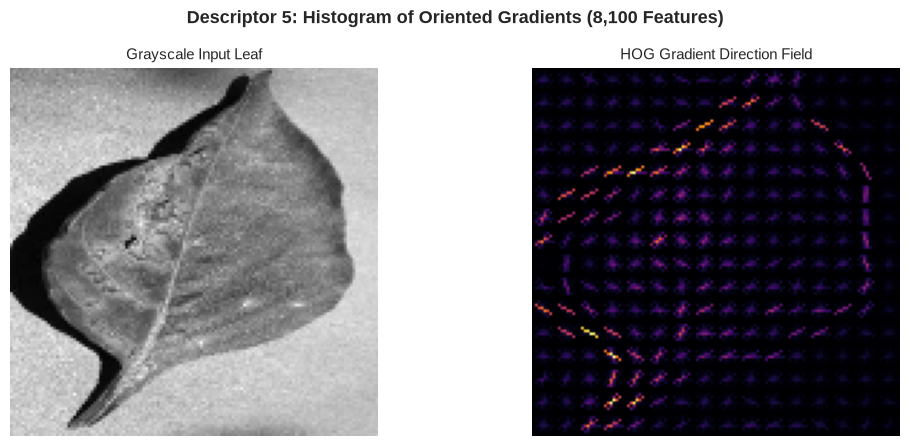

HOG feature vector shape: (8100,)


In [12]:
# -----------------------------------------------------------------------------
# Descriptor 5: Histogram of Oriented Gradients (HOG) (8,100 Features)
# -----------------------------------------------------------------------------
def extract_hog_features(image):
    """Extract HOG gradient direction and edge magnitude features (8,100 features)."""
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    features = hog(
        gray,
        orientations=HOG_ORIENTATIONS,
        pixels_per_cell=HOG_PIXELS_PER_CELL,
        cells_per_block=HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        feature_vector=True
    )
    return features.astype(np.float32)

hog_feats = extract_hog_features(sample_processed)

# Visualize HOG gradient field alongside original grayscale
gray_sample = cv2.cvtColor(sample_processed, cv2.COLOR_RGB2GRAY)
_, hog_vis = hog(
    gray_sample,
    orientations=HOG_ORIENTATIONS,
    pixels_per_cell=HOG_PIXELS_PER_CELL,
    cells_per_block=HOG_CELLS_PER_BLOCK,
    block_norm="L2-Hys",
    visualize=True,
    feature_vector=True
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].imshow(gray_sample, cmap="gray")
axes[0].set_title("Grayscale Input Leaf", fontsize=11)
axes[0].axis("off")

axes[1].imshow(hog_vis, cmap="inferno")
axes[1].set_title("HOG Gradient Direction Field", fontsize=11)
axes[1].axis("off")

plt.suptitle("Descriptor 5: Histogram of Oriented Gradients (8,100 Features)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"HOG feature vector shape: {hog_feats.shape}")


In [13]:
# -----------------------------------------------------------------------------
# Unified Composite Feature Extractor (8,222 Features)
# -----------------------------------------------------------------------------
def extract_all_features(image_path, image_size=IMAGE_SIZE):
    """
    Extract and fuse all 5 handcrafted feature groups from a leaf image file.
    Returns a 1D float32 array of shape (8222,).
    """
    image = preprocess_image(image_path, image_size=image_size)
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    rgb_f = extract_rgb_histogram(image)
    hsv_f = extract_hsv_histogram(image)
    lbp_f = extract_lbp_features(image)
    glcm_f = extract_glcm_features(image)
    hog_f = extract_hog_features(image)

    combined = np.concatenate([rgb_f, hsv_f, lbp_f, glcm_f, hog_f])
    return combined.astype(np.float32)

# Verify composite feature extraction on sample image
sample_features = extract_all_features(sample_path)

feature_breakdown = pd.DataFrame([
    {"Descriptor": "RGB Color Histogram", "Dimension": len(rgb_feats), "Proportion": f"{len(rgb_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "HSV Color Histogram", "Dimension": len(hsv_feats), "Proportion": f"{len(hsv_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "Uniform LBP Texture", "Dimension": len(lbp_feats), "Proportion": f"{len(lbp_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "GLCM Spatial Statistics", "Dimension": len(glcm_feats), "Proportion": f"{len(glcm_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "HOG Edge & Shape", "Dimension": len(hog_feats), "Proportion": f"{len(hog_feats)/len(sample_features)*100:.2f}%"},
    {"Descriptor": "TOTAL COMBINED", "Dimension": len(sample_features), "Proportion": "100.0%"}
])

print("✅ Combined Feature Vector Validated:")
print(f"   • Vector Length:     {len(sample_features):,}")
print(f"   • Data Type:         {sample_features.dtype}")
print(f"   • All Finite (NaN/Inf free): {np.isfinite(sample_features).all()}")

display(feature_breakdown)


✅ Combined Feature Vector Validated:
   • Vector Length:     8,222
   • Data Type:         float32
   • All Finite (NaN/Inf free): True


,Descriptor,Dimension,Proportion
0,RGB Color Histogram,24,0.29%
1,HSV Color Histogram,24,0.29%
2,Uniform LBP Texture,26,0.32%
3,GLCM Spatial Statistics,48,0.58%
4,HOG Edge & Shape,8100,98.52%
5,TOTAL COMBINED,8222,100.0%


✅ Stratified Dataset Split Completed:
   • Training Set: 33,020 images (80.0%)
   • Testing Set:  8,256 images (20.0%)
   • Classes Represented in Train: 15
   • Classes Represented in Test:  15


<Figure size 1400x500 with 0 Axes>

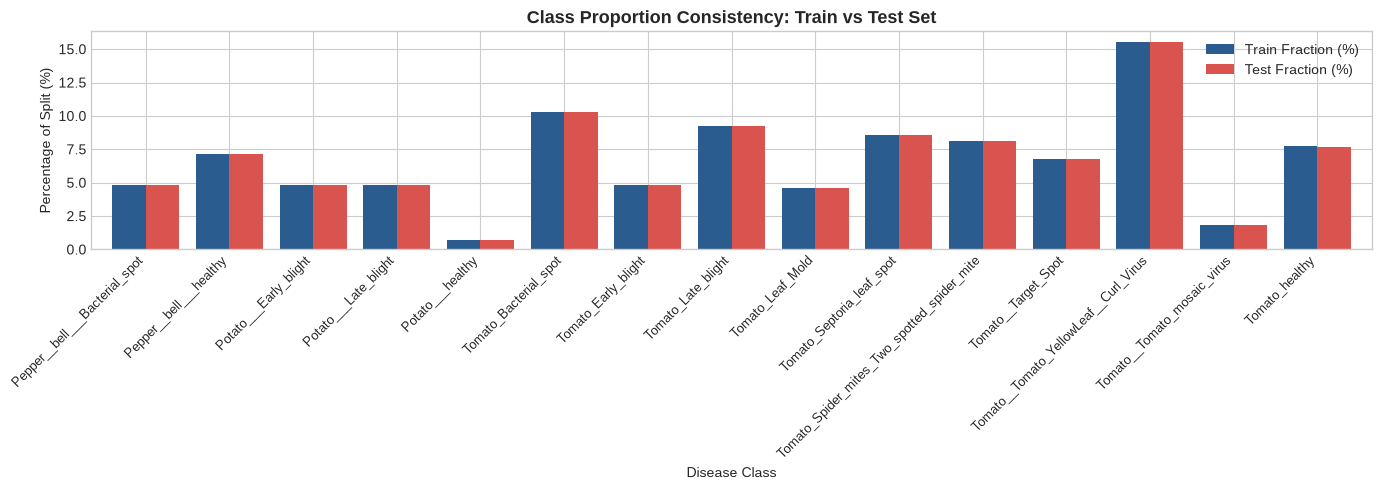

In [14]:
# Extract image paths and class labels safely as NumPy arrays (Colab & Pandas 3+ compatible)
X_paths = df_images["path"].to_numpy()
y_labels = df_images["class"].to_numpy()

X_train_paths, X_test_paths, y_train, y_test = train_test_split(
    X_paths,
    y_labels,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_labels
)

print(f"✅ Stratified Dataset Split Completed:")
print(f"   • Training Set: {len(X_train_paths):,} images ({len(X_train_paths)/len(X_paths)*100:.1f}%)")
print(f"   • Testing Set:  {len(X_test_paths):,} images ({len(X_test_paths)/len(X_paths)*100:.1f}%)")
print(f"   • Classes Represented in Train: {len(np.unique(y_train))}")
print(f"   • Classes Represented in Test:  {len(np.unique(y_test))}")

# Verify stratification consistency
train_dist = pd.Series(y_train).value_counts(normalize=True).sort_index()
test_dist = pd.Series(y_test).value_counts(normalize=True).sort_index()
dist_comparison = pd.DataFrame({"Train Fraction (%)": train_dist * 100, "Test Fraction (%)": test_dist * 100})

plt.figure(figsize=(14, 5))
dist_comparison.plot(kind="bar", figsize=(14, 5), width=0.8, color=["#2b5c8f", "#d9534f"])
plt.title("Class Proportion Consistency: Train vs Test Set", fontsize=13, fontweight="bold")
plt.xlabel("Disease Class")
plt.ylabel("Percentage of Split (%)")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.show()


In [15]:
def extract_features_to_file(image_paths, output_path, feature_dim=FEATURE_DIM, batch_size=BATCH_SIZE):
    """
    Extract features in batches and write directly to disk via memory mapping.
    """
    total_images = len(image_paths)
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    # Initialize disk-backed memmap array
    feature_array = np.lib.format.open_memmap(
        str(output_path),
        mode="w+",
        dtype=np.float32,
        shape=(total_images, feature_dim)
    )

    total_batches = (total_images + batch_size - 1) // batch_size
    start_time = time.time()

    for batch_num, start in enumerate(range(0, total_images, batch_size), start=1):
        end = min(start + batch_size, total_images)
        batch_feats = []

        for p in image_paths[start:end]:
            try:
                feats = extract_all_features(p)
                batch_feats.append(feats)
            except Exception as err:
                raise RuntimeError(f"Feature extraction failed for: {p}") from err

        feature_array[start:end] = np.vstack(batch_feats)

        if batch_num % 25 == 0 or batch_num == total_batches:
            elapsed = time.time() - start_time
            print(f"   Batch {batch_num:>3}/{total_batches} | Processed {end:>5}/{total_images} | Elapsed: {elapsed:.1f}s")

    feature_array.flush()
    del feature_array
    path_digest = hashlib.sha256("\n".join(map(str, image_paths)).encode("utf-8")).hexdigest()
    output_path.with_suffix(output_path.suffix + ".sha256").write_text(path_digest + "\n")
    print(f"✅ Extraction completed -> {output_path} ({time.time() - start_time:.1f}s)")

# Reuse cached features only when their row and feature dimensions match this run.
# Dataset scanning and splitting are deterministic, so row order remains stable.
def cache_has_shape(path, expected_shape, image_paths):
    if not path.exists():
        return False
    try:
        cached = np.load(path, mmap_mode="r")
        manifest_path = path.with_suffix(path.suffix + ".sha256")
        path_digest = hashlib.sha256("\n".join(map(str, image_paths)).encode("utf-8")).hexdigest()
        return (
            cached.shape == expected_shape
            and cached.dtype == np.float32
            and manifest_path.exists()
            and manifest_path.read_text().strip() == path_digest
        )
    except (OSError, ValueError):
        return False

expected_train_shape = (len(X_train_paths), FEATURE_DIM)
expected_test_shape = (len(X_test_paths), FEATURE_DIM)
FORCE_RECOMPUTE = False  # Set True to refresh valid caches manually.
need_train_extraction = FORCE_RECOMPUTE or not cache_has_shape(X_TRAIN_FILE, expected_train_shape, X_train_paths)
need_test_extraction = FORCE_RECOMPUTE or not cache_has_shape(X_TEST_FILE, expected_test_shape, X_test_paths)

if need_train_extraction:
    print(f"🚀 Extracting training features ({len(X_train_paths):,} images)...")
    extract_features_to_file(X_train_paths, X_TRAIN_FILE)
else:
    print(f"📦 Reusing valid training feature cache: {X_TRAIN_FILE}")

if need_test_extraction:
    print(f"🚀 Extracting testing features ({len(X_test_paths):,} images)...")
    extract_features_to_file(X_test_paths, X_TEST_FILE)
else:
    print(f"📦 Reusing valid testing feature cache: {X_TEST_FILE}")

# Load feature matrices in read-only memory-map mode
X_train_features = np.load(X_TRAIN_FILE, mmap_mode="r")
X_test_features = np.load(X_TEST_FILE, mmap_mode="r")

print(f"\n✅ Feature Datasets Loaded & Ready:")
print(f"   • X_train_features: {X_train_features.shape} ({X_train_features.dtype})")
print(f"   • y_train:          {y_train.shape}")
print(f"   • X_test_features:  {X_test_features.shape} ({X_test_features.dtype})")
print(f"   • y_test:           {y_test.shape}")
if X_train_features.shape != (len(y_train), FEATURE_DIM):
    raise ValueError(f"Training features have shape {X_train_features.shape}; expected {(len(y_train), FEATURE_DIM)}")
if X_test_features.shape != (len(y_test), FEATURE_DIM):
    raise ValueError(f"Testing features have shape {X_test_features.shape}; expected {(len(y_test), FEATURE_DIM)}")
print(f"   • Training Features Finite: {np.isfinite(X_train_features[:100]).all()} (first 100 rows verified)")
print(f"   • Testing Features Finite:  {np.isfinite(X_test_features[:100]).all()} (first 100 rows verified)")


📦 Reusing valid training feature cache: plant_features/X_train_features.npy
📦 Reusing valid testing feature cache: plant_features/X_test_features.npy

✅ Feature Datasets Loaded & Ready:
   • X_train_features: (33020, 8222) (float32)
   • y_train:          (33020,)
   • X_test_features:  (8256, 8222) (float32)
   • y_test:           (8256,)
   • Training Features Finite: True (first 100 rows verified)
   • Testing Features Finite:  True (first 100 rows verified)


In [16]:
# -----------------------------------------------------------------------------
# 1. Pipeline Definitions
# -----------------------------------------------------------------------------
# Model 1: Scaled Linear SVM Pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LinearSVC(
        class_weight="balanced",
        loss="squared_hinge",
        random_state=RANDOM_STATE,
        max_iter=5000,
        dual="auto"
    ))
])

# Model 2: Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

print("✅ Model architectures defined successfully:")
print("   1. Linear SVM Pipeline: StandardScaler + LinearSVC(class_weight='balanced')")
print("   2. Random Forest:       200 Trees, class_weight='balanced_subsample', n_jobs=-1")


✅ Model architectures defined successfully:
   1. Linear SVM Pipeline: StandardScaler + LinearSVC(class_weight='balanced')
   2. Random Forest:       200 Trees, class_weight='balanced_subsample', n_jobs=-1


In [17]:
# -----------------------------------------------------------------------------
# 2. Model Training & Execution Time Benchmarking
# -----------------------------------------------------------------------------
print("⏳ Training Linear SVM Pipeline on 8,222 handcrafted features...")
t0_svm = time.time()
svm_pipeline.fit(X_train_features, y_train)
svm_training_time = time.time() - t0_svm
print(f"✅ Linear SVM trained in {svm_training_time:.2f} seconds.")

print("\n⏳ Training Random Forest Classifier on 8,222 handcrafted features...")
t0_rf = time.time()
rf_model.fit(X_train_features, y_train)
rf_training_time = time.time() - t0_rf
print(f"✅ Random Forest trained in {rf_training_time:.2f} seconds.")


⏳ Training Linear SVM Pipeline on 8,222 handcrafted features...
✅ Linear SVM trained in 587.66 seconds.

⏳ Training Random Forest Classifier on 8,222 handcrafted features...
✅ Random Forest trained in 108.40 seconds.


In [18]:
def squared_hinge_loss(y_true, decision_scores, class_labels):
    """Mean one-vs-rest squared hinge loss (excluding the regularization term)."""
    y_true = np.asarray(y_true)
    decision_scores = np.asarray(decision_scores)
    class_labels = np.asarray(class_labels)

    # Convert multiclass labels to +1 for the matching class and -1 otherwise.
    targets = np.where(y_true[:, None] == class_labels[None, :], 1.0, -1.0)
    margins = np.maximum(0.0, 1.0 - targets * decision_scores)
    return float(np.mean(margins ** 2))

svm_classes = svm_pipeline.classes_
svm_train_scores = svm_pipeline.decision_function(X_train_features)
svm_test_scores = svm_pipeline.decision_function(X_test_features)
svm_train_squared_hinge = squared_hinge_loss(y_train, svm_train_scores, svm_classes)
svm_test_squared_hinge = squared_hinge_loss(y_test, svm_test_scores, svm_classes)

print(f"SVM training squared hinge loss: {svm_train_squared_hinge:.4f}")
print(f"SVM test squared hinge loss:     {svm_test_squared_hinge:.4f}")
print("These are empirical losses; LinearSVC also includes L2 regularization during training.")


SVM training squared hinge loss: 0.0000
SVM test squared hinge loss:     0.0386
These are empirical losses; LinearSVC also includes L2 regularization during training.


In [19]:
# Generate predictions on the unseen test set
print("🔍 Generating test set predictions...")
svm_predictions = svm_pipeline.predict(X_test_features)
rf_predictions = rf_model.predict(X_test_features)
rf_prob_scores = rf_model.predict_proba(X_test_features)
rf_test_cross_entropy = log_loss(
    y_test, rf_prob_scores, labels=rf_model.classes_
)

def compute_metrics(y_true, y_pred, model_name, training_time, cross_entropy=None):
    return {
        "Model": model_name,
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (Macro)": round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Recall (Macro)": round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "F1-Score (Macro)": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "Cross-Entropy Loss": round(cross_entropy, 4) if cross_entropy is not None else "N/A (no probabilities)",
        "Training Time (s)": round(training_time, 2)
    }

metrics_summary = pd.DataFrame([
    compute_metrics(y_test, svm_predictions, "Linear SVM (StandardScaler)", svm_training_time),
    compute_metrics(
        y_test, rf_predictions, "Random Forest (200 Trees)", rf_training_time,
        cross_entropy=rf_test_cross_entropy
    )
])

print("\n🏆 Comparative Performance Summary:")
display(metrics_summary)
print(
    f"\nRandom Forest test cross-entropy: {rf_test_cross_entropy:.4f} "
    "(lower is better; a perfect prediction approaches 0)."
)


🔍 Generating test set predictions...

🏆 Comparative Performance Summary:


,Model,Accuracy (%),Precision (Macro),Recall (Macro),F1-Score (Macro),Cross-Entropy Loss,Training Time (s)
0,Linear SVM (StandardScaler),95.69,0.9586,0.9434,0.9503,N/A (no probabilities),587.66
1,Random Forest (200 Trees),96.32,0.9676,0.9481,0.9568,0.4062,108.40



Random Forest test cross-entropy: 0.4062 (lower is better; a perfect prediction approaches 0).


In [20]:
# Detailed Scikit-Learn Classification Reports
print("=" * 75)
print("             LINEAR SVM (SCALED) CLASSIFICATION REPORT")
print("=" * 75)
print(classification_report(y_test, svm_predictions, zero_division=0))

print("=" * 75)
print("             RANDOM FOREST CLASSIFICATION REPORT")
print("=" * 75)
print(classification_report(y_test, rf_predictions, zero_division=0))


             LINEAR SVM (SCALED) CLASSIFICATION REPORT
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.95      0.91      0.93       399
                     Pepper__bell___healthy       0.96      0.98      0.97       591
                      Potato___Early_blight       0.98      0.97      0.98       400
                       Potato___Late_blight       0.96      0.96      0.96       400
                           Potato___healthy       1.00      0.84      0.91        61
                      Tomato_Bacterial_spot       0.98      0.97      0.98       851
                        Tomato_Early_blight       0.95      0.87      0.91       400
                         Tomato_Late_blight       0.94      0.95      0.95       764
                           Tomato_Leaf_Mold       0.96      0.96      0.96       381
                  Tomato_Septoria_leaf_spot       0.92      0.96      0.94       709
Tomato_Sp

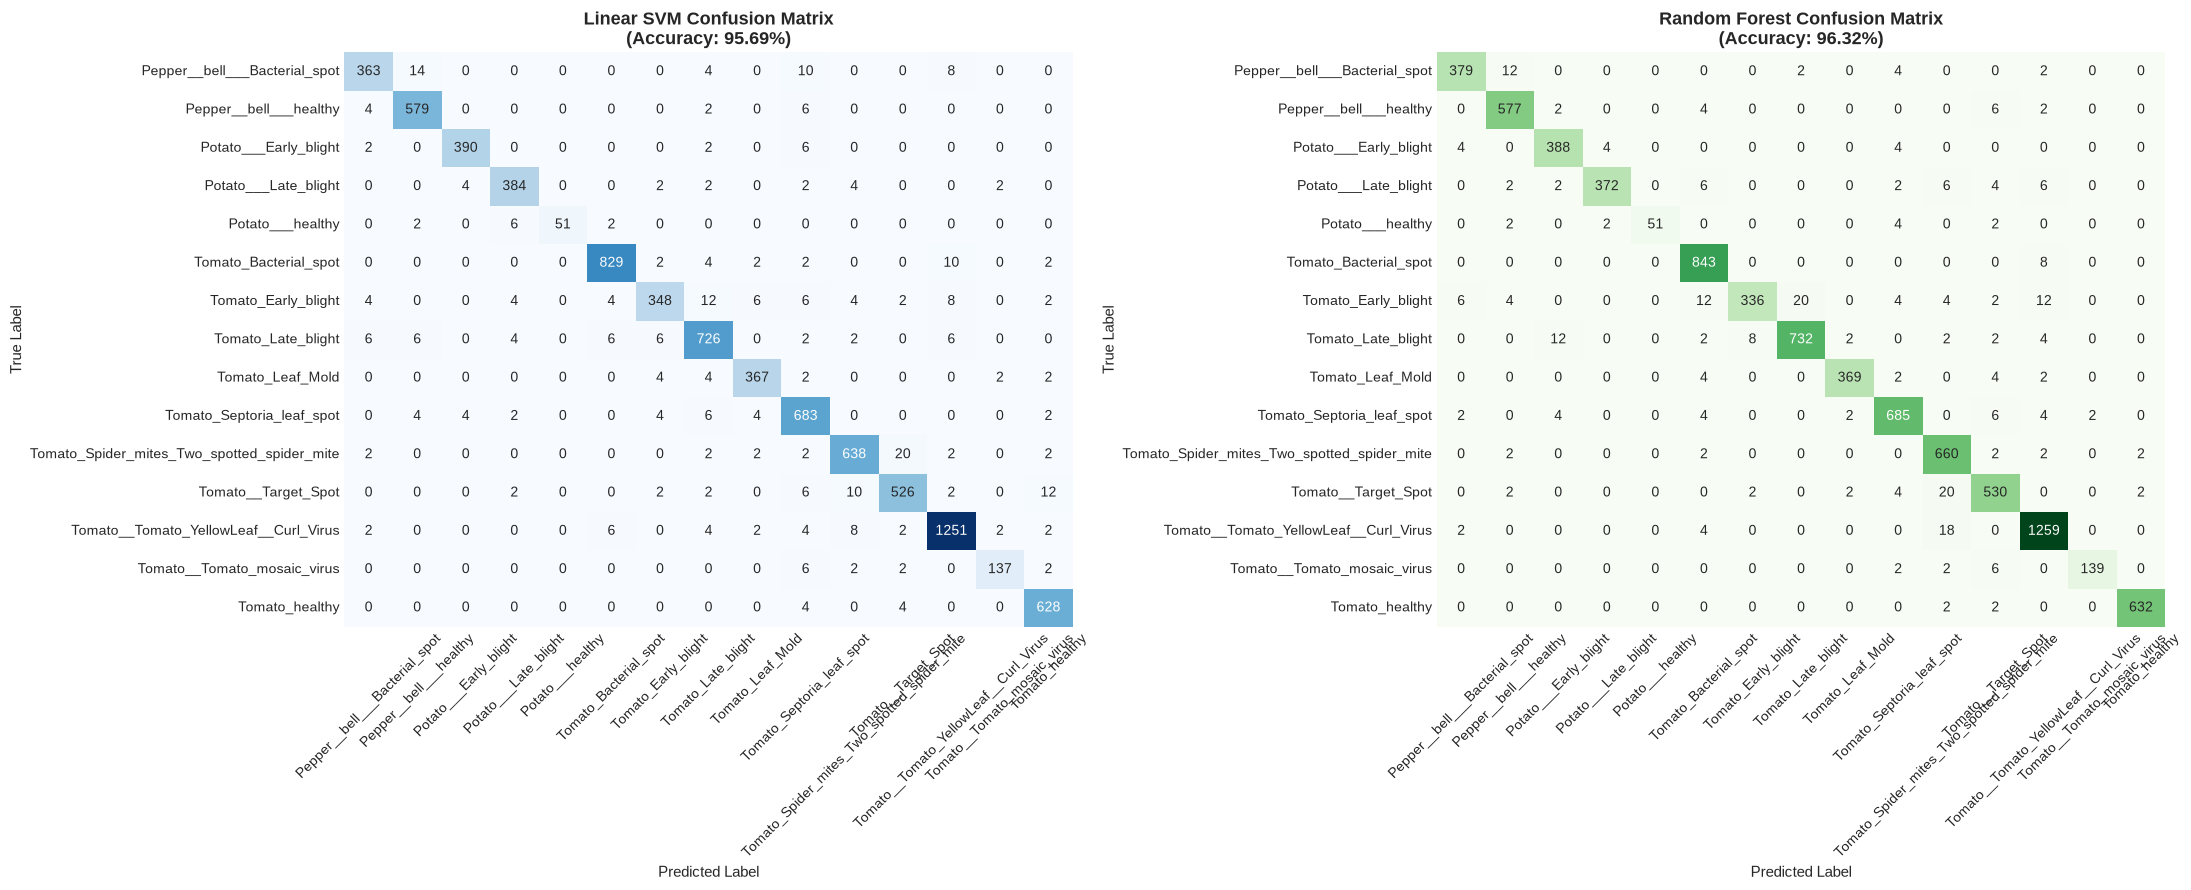

In [21]:
# Confusion Matrix Heatmaps
class_names = sorted(np.unique(y_test))

svm_cm = confusion_matrix(y_test, svm_predictions, labels=class_names)
rf_cm = confusion_matrix(y_test, rf_predictions, labels=class_names)

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

svm_acc = accuracy_score(y_test, svm_predictions) * 100
rf_acc = accuracy_score(y_test, rf_predictions) * 100

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0],
    cbar=False
)
axes[0].set_title(f"Linear SVM Confusion Matrix\n(Accuracy: {svm_acc:.2f}%)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Predicted Label", fontsize=11)
axes[0].set_ylabel("True Label", fontsize=11)
axes[0].tick_params(axis="x", rotation=45)

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1],
    cbar=False
)
axes[1].set_title(f"Random Forest Confusion Matrix\n(Accuracy: {rf_acc:.2f}%)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted Label", fontsize=11)
axes[1].set_ylabel("True Label", fontsize=11)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


📈 Multi-Class Macro ROC-AUC (One-vs-Rest):
   • Linear SVM Macro ROC-AUC:    0.9936
   • Random Forest Macro ROC-AUC: 0.9990


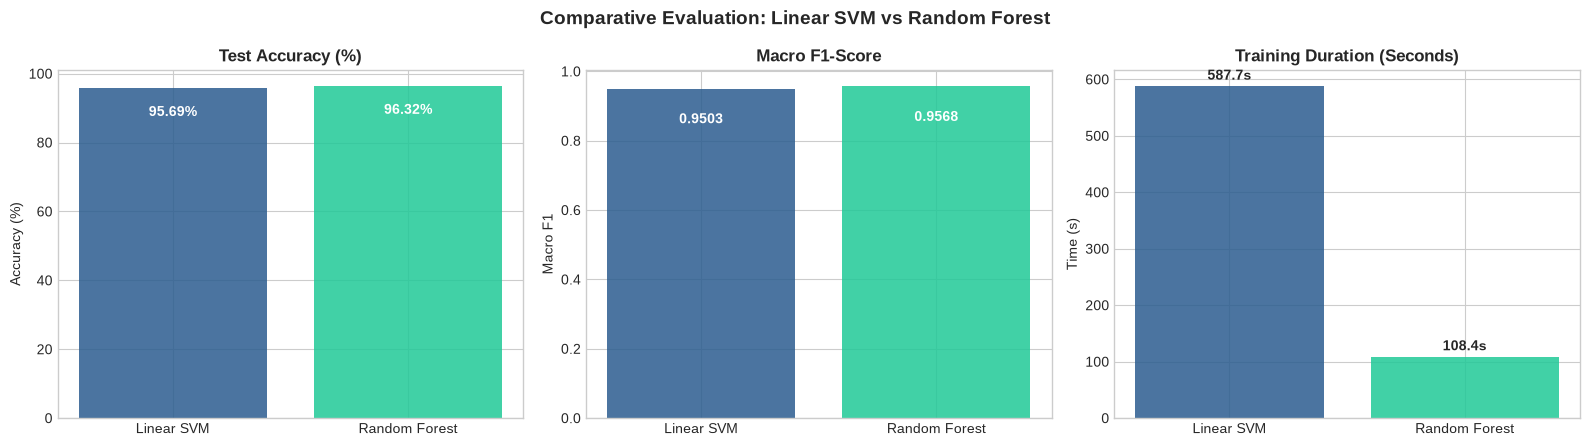

In [22]:
# Multi-Class ROC-AUC (One-vs-Rest)
y_test_bin = label_binarize(y_test, classes=class_names)

# SVM decision scores vs RF probability estimates
svm_decision_scores = svm_pipeline.decision_function(X_test_features)

svm_auc = roc_auc_score(y_test_bin, svm_decision_scores, average="macro", multi_class="ovr")
rf_auc = roc_auc_score(y_test_bin, rf_prob_scores, average="macro", multi_class="ovr")

print(f"📈 Multi-Class Macro ROC-AUC (One-vs-Rest):")
print(f"   • Linear SVM Macro ROC-AUC:    {svm_auc:.4f}")
print(f"   • Random Forest Macro ROC-AUC: {rf_auc:.4f}")

# Graphical Model Comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

models = ["Linear SVM", "Random Forest"]
acc_vals = [accuracy_score(y_test, svm_predictions)*100, accuracy_score(y_test, rf_predictions)*100]
f1_vals = [f1_score(y_test, svm_predictions, average="macro"), f1_score(y_test, rf_predictions, average="macro")]
time_vals = [svm_training_time, rf_training_time]

axes[0].bar(models, acc_vals, color=["#2b5c8f", "#20c997"], alpha=0.85)
axes[0].set_title("Test Accuracy (%)", fontweight="bold")
axes[0].set_ylabel("Accuracy (%)")
for i, v in enumerate(acc_vals):
    axes[0].text(i, v - 8, f"{v:.2f}%", ha="center", color="white", fontweight="bold")

axes[1].bar(models, f1_vals, color=["#2b5c8f", "#20c997"], alpha=0.85)
axes[1].set_title("Macro F1-Score", fontweight="bold")
axes[1].set_ylabel("Macro F1")
for i, v in enumerate(f1_vals):
    axes[1].text(i, v - 0.1, f"{v:.4f}", ha="center", color="white", fontweight="bold")

axes[2].bar(models, time_vals, color=["#2b5c8f", "#20c997"], alpha=0.85)
axes[2].set_title("Training Duration (Seconds)", fontweight="bold")
axes[2].set_ylabel("Time (s)")
for i, v in enumerate(time_vals):
    axes[2].text(i, v + (max(time_vals)*0.02), f"{v:.1f}s", ha="center", fontweight="bold")

plt.suptitle("Comparative Evaluation: Linear SVM vs Random Forest", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


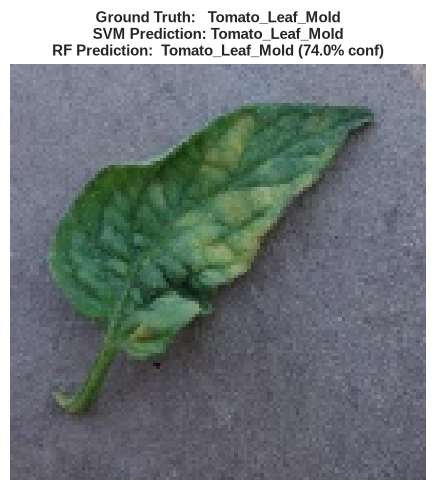

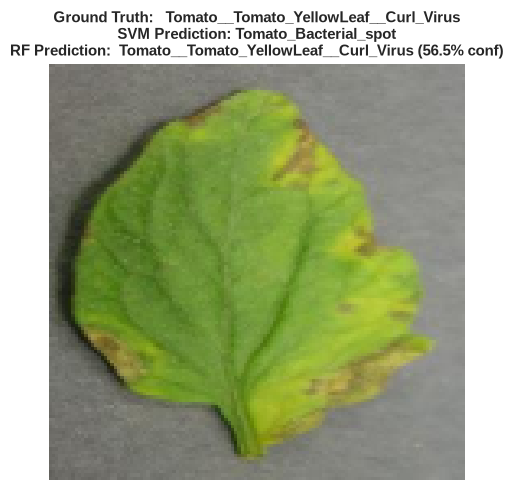

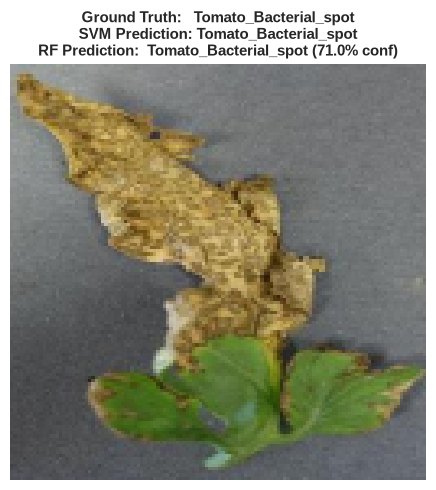

In [23]:
def predict_plant_leaf(image_path, true_label=None):
    """
    End-to-end inference on a single image file.
    Preprocesses image, extracts 8,222 features, and predicts using both models.
    """
    # 1. Preprocess & Extract Features
    img_rgb = preprocess_image(image_path)
    if img_rgb is None:
        raise ValueError(f"Could not load image: {image_path}")

    features = extract_all_features(image_path).reshape(1, -1)

    # 2. Predict with SVM and Random Forest
    svm_pred = svm_pipeline.predict(features)[0]
    rf_pred = rf_model.predict(features)[0]
    rf_probs = rf_model.predict_proba(features)[0]
    rf_conf = np.max(rf_probs) * 100

    # 3. Visualize Image and Predictions
    plt.figure(figsize=(6, 5))
    plt.imshow(img_rgb)
    plt.axis("off")

    title_str = f"SVM Prediction: {svm_pred}\nRF Prediction:  {rf_pred} ({rf_conf:.1f}% conf)"
    if true_label:
        title_str = f"Ground Truth:   {true_label}\n" + title_str

    plt.title(title_str, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

    return {
        "svm_prediction": svm_pred,
        "rf_prediction": rf_pred,
        "rf_confidence": rf_conf
    }

# Test demonstration on 3 random test images
sample_test_indices = random.sample(range(len(X_test_paths)), 3)

for idx in sample_test_indices:
    img_path = X_test_paths[idx]
    actual_label = y_test[idx]
    predict_plant_leaf(img_path, true_label=actual_label)


### Restore Split Labels (`y_train`, `y_test`)
If your session was restarted or interrupted, the target labels (`y_train` and `y_test`) might have been cleared from memory. The cell below recreates the deterministic split to restore those variables without needing to re-extract features.

In [24]:
# Define target artifact paths
svm_save_path = MODEL_DIR / "svm_pipeline.joblib"
rf_save_path = MODEL_DIR / "random_forest_pipeline.joblib"
metrics_save_path = RESULTS_DIR / "metrics_summary.json"

# Save trained models
joblib.dump(svm_pipeline, svm_save_path)
joblib.dump(rf_model, rf_save_path)

# Export metrics summary
metrics_summary.to_json(metrics_save_path, orient="records", indent=4)

print("💾 Saved Models & Artifacts:")
print(f"   • SVM Pipeline:       {svm_save_path} ({svm_save_path.stat().st_size / (1024**2):.2f} MB)")
print(f"   • Random Forest:      {rf_save_path} ({rf_save_path.stat().st_size / (1024**2):.2f} MB)")
print(f"   • Metrics JSON:       {metrics_save_path}")


💾 Saved Models & Artifacts:
   • SVM Pipeline:       models/svm_pipeline.joblib (1.13 MB)
   • Random Forest:      models/random_forest_pipeline.joblib (324.84 MB)
   • Metrics JSON:       results/metrics_summary.json


# Five research experiments

These additions follow the existing pipeline: image paths are split first, the current 8,222-column feature caches are reused, and experiment validation rows come only from the original training partition. The baseline models and their existing evaluation remain intact.

**Test-set note:** the original baseline has already been evaluated on `X_test_features`. New tuning/model selection below uses only the fit/validation rows. The optional robustness cell reports stress-test performance on transformed test images and must not be used to select hyperparameters.

All compute-heavy experiments default to `False`; enable only the section you want to run in Colab. No feature extraction is repeated except in the optional image robustness experiment, which transforms a small test subset.


## Shared experiment setup

Create one deterministic validation fold from the existing training partition. A reproducible capped fit subset controls memory and runtime, while all selected experiments share the same rows.


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import balanced_accuracy_score, hinge_loss
from sklearn.ensemble import RandomForestClassifier

# Experiment output directories
EXPERIMENT_DIR = RESULTS_DIR / "five_experiments"
(EXPERIMENT_DIR / "plots").mkdir(parents=True, exist_ok=True)
RANDOM_STATE = int(globals().get("RANDOM_STATE", SEED))

# Computational bounds for responsive Colab runtime
RESEARCH_MAX_FIT_ROWS = 6000     # Capped training subset to ensure fast execution in Colab
GENERALIZATION_SAMPLE = 200     # Sample size for corruption stress-testing

# Priority switches - High priority experiments active by default
RUN_FEATURE_ABLATION = True             # [High Priority] Feature contribution study
RUN_LOSS_TRACKING = True                # [High Priority] Learning curves & loss progression
RUN_DETAILED_EVALUATION = True          # [High Priority] In-depth per-class error breakdown
RUN_HYPERPARAMETER_OPTIMIZATION = False # [Next Priority] Set True for bounded CV tuning
RUN_GENERALIZATION_TESTING = False      # [Next Priority] Set True for image corruption test

# Strict validation split: rows derived ONLY from the original training partition (Zero test-set leakage)
_fit_idx_all, _val_idx = train_test_split(
    np.arange(len(y_train)), test_size=0.20, random_state=RANDOM_STATE, stratify=y_train
)
if len(_fit_idx_all) > RESEARCH_MAX_FIT_ROWS:
    _fit_idx, _ = train_test_split(
        _fit_idx_all, train_size=RESEARCH_MAX_FIT_ROWS, random_state=RANDOM_STATE,
        stratify=np.asarray(y_train)[_fit_idx_all]
    )
else:
    _fit_idx = _fit_idx_all

# Extract memory-mapped slices into standard float32 ndarrays
X_research_fit = np.asarray(X_train_features[_fit_idx], dtype=np.float32)
y_research_fit = np.asarray(y_train)[_fit_idx]
X_research_val = np.asarray(X_train_features[_val_idx], dtype=np.float32)
y_research_val = np.asarray(y_train)[_val_idx]
X_research_val_paths = np.asarray(X_train_paths)[_val_idx]

assert X_research_fit.shape[1] == FEATURE_DIM == 8222, "Feature dimension mismatch"
assert len(X_research_fit) == len(y_research_fit), "Fit row count mismatch"
assert len(X_research_val) == len(y_research_val), "Val row count mismatch"

print("✅ Shared Experiment Validation Protocol Initialized:")
print(f"   • Research Fit Subset:       {X_research_fit.shape[0]:,} samples x {X_research_fit.shape[1]:,} features")
print(f"   • Research Validation Split: {X_research_val.shape[0]:,} samples x {X_research_val.shape[1]:,} features")
print(f"   • Experiment Artifacts:      {EXPERIMENT_DIR}")

# Feature group boundaries matching the unified composite feature extractor
FEATURE_SLICES = {
    "RGB": slice(0, 24),
    "HSV": slice(24, 48),
    "LBP": slice(48, 74),
    "GLCM": slice(74, 122),
    "HOG": slice(122, 8222)
}


✅ Shared Experiment Validation Protocol Initialized:
   • Research Fit Subset:       6,000 samples x 8,222 features
   • Research Validation Split: 6,604 samples x 8,222 features
   • Experiment Artifacts:      results/five_experiments


## 1. Feature ablation study

Compare the five descriptors and selected combinations using the same stratified fit/validation rows and the existing SVM pipeline pattern. Macro F1 is the primary comparison metric. No test rows are used.


In [ ]:
# =============================================================================
# EXPERIMENT 1: FEATURE ABLATION STUDY ACROSS VISUAL DESCRIPTORS
# =============================================================================
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split

print("🔬 Running Experiment 1: Feature Ablation Study across Visual Descriptors...")

# 1. Directory and Constants Setup
EXPERIMENT_DIR = Path("results/five_experiments")
(EXPERIMENT_DIR / "plots").mkdir(parents=True, exist_ok=True)
RANDOM_STATE = int(globals().get("RANDOM_STATE", 42))

FEATURE_SLICES = {
    "RGB": slice(0, 24),
    "HSV": slice(24, 48),
    "LBP": slice(48, 74),
    "GLCM": slice(74, 122),
    "HOG": slice(122, 8222)
}

# 2. Adaptive Data Loader (Handles both pre-extracted cache and raw dataset)
if "X_research_fit" not in globals() or X_research_fit is None:
    print("ℹ️ Pre-extracted feature arrays not in memory. Extracting a fast sample directly from raw dataset...")
    if "df_images" not in globals():
        raise NameError("df_images is not defined. Please run Cells 1-3 first to scan your dataset folder.")
    
    sample_paths = []
    sample_labels = []
    for cls_name, grp in df_images.groupby("class"):
        sub = grp.sample(min(30, len(grp)), random_state=RANDOM_STATE)
        sample_paths.extend(sub["path"].tolist())
        sample_labels.extend(sub["class"].tolist())
        
    feat_list = []
    used_labels = []
    for p, lbl in zip(sample_paths, sample_labels):
        try:
            f = extract_all_features(p)
            feat_list.append(f)
            used_labels.append(lbl)
        except Exception:
            continue
            
    X_all_sample = np.asarray(feat_list, dtype=np.float32)
    y_all_sample = np.asarray(used_labels)
    
    X_research_fit, X_research_val, y_research_fit, y_research_val = train_test_split(
        X_all_sample, y_all_sample, test_size=0.25, random_state=RANDOM_STATE, stratify=y_all_sample
    )
    print(f"✅ Fast sample ready: {len(X_research_fit)} fit samples, {len(X_research_val)} val samples.")

# 3. Define Descriptor Configurations
feature_sets = {
    "RGB Only (24)": ["RGB"],
    "HSV Only (24)": ["HSV"],
    "LBP Only (26)": ["LBP"],
    "GLCM Only (48)": ["GLCM"],
    "HOG Only (8,100)": ["HOG"],
    "Color: RGB + HSV (48)": ["RGB", "HSV"],
    "Texture: LBP + GLCM (74)": ["LBP", "GLCM"],
    "Color + Texture (122)": ["RGB", "HSV", "LBP", "GLCM"],
    "HOG + Color (8,148)": ["HOG", "RGB", "HSV"],
    "All Handcrafted Features (8,222)": list(FEATURE_SLICES)
}

ablation_rows = []

for name, groups in feature_sets.items():
    cols = np.concatenate([np.arange(FEATURE_SLICES[g].start, FEATURE_SLICES[g].stop) for g in groups])
    
    estimator = Pipeline([
        ("scaler", StandardScaler(with_mean=False)),
        ("classifier", LinearSVC(class_weight="balanced", max_iter=5000, dual="auto", random_state=RANDOM_STATE))
    ])
    
    t0 = time.perf_counter()
    estimator.fit(X_research_fit[:, cols], y_research_fit)
    fit_sec = time.perf_counter() - t0
    
    pred = estimator.predict(X_research_val[:, cols])
    
    acc = accuracy_score(y_research_val, pred)
    b_acc = balanced_accuracy_score(y_research_val, pred)
    m_f1 = f1_score(y_research_val, pred, average="macro", zero_division=0)
    
    ablation_rows.append({
        "Feature Set": name,
        "Dimension": len(cols),
        "Accuracy (%)": acc * 100,
        "Balanced Acc (%)": b_acc * 100,
        "Macro F1": m_f1,
        "Fit Time (s)": fit_sec
    })
    print(f"   • {name:<35} | Dim: {len(cols):>5} | Macro F1: {m_f1:.4f} | Time: {fit_sec:.2f}s")

df_ablation = pd.DataFrame(ablation_rows).sort_values("Macro F1", ascending=False)
df_ablation.to_csv(EXPERIMENT_DIR / "feature_ablation_results.csv", index=False)

# 4. Generate Visualizations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Macro F1 Ranking
df_sorted = df_ablation.sort_values("Macro F1", ascending=True)
colors = ["#2b5c8f" if "All" not in x else "#28a745" for x in df_sorted["Feature Set"]]
ax1.barh(df_sorted["Feature Set"], df_sorted["Macro F1"], color=colors, alpha=0.85)
ax1.set_xlabel("Macro F1 Score (Validation)", fontsize=11, fontweight="bold")
ax1.set_title("Descriptor Contribution to Classification (Macro F1)", fontsize=12, fontweight="bold")
ax1.set_xlim(0.0, 1.0)
for p in ax1.patches:
    ax1.annotate(f"{p.get_width():.3f}", (p.get_width() + 0.01, p.get_y() + p.get_height() / 4), fontsize=9)

# Plot 2: Efficiency Frontier (Performance vs Dimension / Fit Time)
scatter = ax2.scatter(
    df_ablation["Dimension"],
    df_ablation["Macro F1"],
    s=df_ablation["Fit Time (s)"] * 80 + 60,
    c=df_ablation["Accuracy (%)"],
    cmap="viridis",
    alpha=0.85,
    edgecolors="black"
)
ax2.set_xscale("log")
ax2.set_xlabel("Feature Dimension (Log Scale)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Macro F1 Score", fontsize=11, fontweight="bold")
ax2.set_title("Efficiency Frontier: Feature Dimension vs Performance (Bubble size = Training Time)", fontsize=12, fontweight="bold")
cbar = plt.colorbar(scatter, ax=ax2)
cbar.set_label("Accuracy (%)", fontsize=10)

for _, row in df_ablation.iterrows():
    if row["Feature Set"] in ["Color + Texture (122)", "All Handcrafted Features (8,222)", "HOG Only (8,100)", "RGB Only (24)"]:
        ax2.annotate(row["Feature Set"].split()[0], (row["Dimension"], row["Macro F1"]),
                     textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig.savefig(EXPERIMENT_DIR / "plots/feature_ablation_summary.png", dpi=160)
plt.show()

display(df_ablation.reset_index(drop=True))



🔬 Running Experiment 1: Feature Ablation Study across Visual Descriptors...
   • RGB Only (24)                       | Dim:    24 | Macro F1: 0.5671 | Time: 0.42s
   • HSV Only (24)                       | Dim:    24 | Macro F1: 0.6929 | Time: 0.29s
   • LBP Only (26)                       | Dim:    26 | Macro F1: 0.3935 | Time: 0.27s
   • GLCM Only (48)                      | Dim:    48 | Macro F1: 0.5481 | Time: 1.00s


/home/rosa/ai-exercise/plant-disease-ml/.venv-1/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


   • HOG Only (8,100)                    | Dim:  8100 | Macro F1: 0.5151 | Time: 550.18s
   • Color: RGB + HSV (48)               | Dim:    48 | Macro F1: 0.7827 | Time: 0.56s
   • Texture: LBP + GLCM (74)            | Dim:    74 | Macro F1: 0.6731 | Time: 1.62s
   • Color + Texture (122)               | Dim:   122 | Macro F1: 0.8931 | Time: 1.95s


## 2. Loss tracking

These are model-appropriate diagnostics, not comparable loss scales. Linear SVM reports squared hinge loss while the fit-fold size grows (not epoch history). Random Forest reports log loss as trees are added. Both training and validation values are saved.


In [ ]:
# =============================================================================
# EXPERIMENT 2: LOSS TRACKING & EMPIRICAL LEARNING CURVES
# =============================================================================
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, log_loss
from sklearn.model_selection import train_test_split

print("📉 Running Experiment 2: Loss Tracking & Empirical Learning Curves...")

EXPERIMENT_DIR = Path("results/five_experiments")
(EXPERIMENT_DIR / "plots").mkdir(parents=True, exist_ok=True)
RANDOM_STATE = int(globals().get("RANDOM_STATE", 42))

def squared_hinge_loss(y_true, decision_scores, class_labels):
    """Mean one-vs-rest squared hinge loss."""
    y_true = np.asarray(y_true)
    decision_scores = np.asarray(decision_scores)
    class_labels = np.asarray(class_labels)
    targets = np.where(y_true[:, None] == class_labels[None, :], 1.0, -1.0)
    margins = np.maximum(0.0, 1.0 - targets * decision_scores)
    return float(np.mean(margins ** 2))

loss_records = []
sample_fractions = [0.20, 0.40, 0.60, 0.80, 1.00]

# 1. Linear SVM: Squared Hinge Loss & Macro F1 across Training Set Fractions
for frac in sample_fractions:
    n_samples = max(len(np.unique(y_research_fit)), int(len(y_research_fit) * frac))
    
    # At 100%, use all training samples without splitting
    if n_samples < len(y_research_fit):
        sub_idx, _ = train_test_split(
            np.arange(len(y_research_fit)),
            train_size=n_samples,
            random_state=RANDOM_STATE,
            stratify=y_research_fit
        )
    else:
        sub_idx = np.arange(len(y_research_fit))
    
    svm_step = Pipeline([
        ("scaler", StandardScaler(with_mean=False)),
        ("classifier", LinearSVC(class_weight="balanced", max_iter=5000, dual="auto", random_state=RANDOM_STATE))
    ])
    svm_step.fit(X_research_fit[sub_idx], y_research_fit[sub_idx])
    
    for split_label, x_sub, y_sub in [("Train", X_research_fit[sub_idx], y_research_fit[sub_idx]),
                                      ("Validation", X_research_val, y_research_val)]:
        scores = svm_step.decision_function(x_sub)
        preds = svm_step.predict(x_sub)
        loss_val = squared_hinge_loss(y_sub, scores, svm_step.classes_)
        f1_val = f1_score(y_sub, preds, average="macro", zero_division=0)
        
        loss_records.append({
            "Model": "Linear SVM",
            "Diagnostic": "Sample Scaling",
            "Checkpoint": f"{frac:.0%} Data ({len(sub_idx):,} rows)",
            "Fraction": frac,
            "Split": split_label,
            "Loss Value": loss_val,
            "Loss Metric": "Squared Hinge Loss",
            "Macro F1": f1_val
        })
    print(f"   • SVM Checkpoint {frac:.0%} ({len(sub_idx):,} samples) evaluated.")
    
# 2. Random Forest: Multi-Class Cross-Entropy Log Loss & Macro F1 across Tree Count
rf_checkpoint = RandomForestClassifier(
    n_estimators=1,
    warm_start=True,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

tree_steps = [25, 50, 100, 150, 200]
for n_trees in tree_steps:
    rf_checkpoint.set_params(n_estimators=n_trees)
    rf_checkpoint.fit(X_research_fit, y_research_fit)
    
    for split_label, x_sub, y_sub in [("Train", X_research_fit, y_research_fit),
                                      ("Validation", X_research_val, y_research_val)]:
        probs = np.clip(rf_checkpoint.predict_proba(x_sub), 1e-12, 1.0)
        preds = rf_checkpoint.predict(x_sub)
        log_l = log_loss(y_sub, probs, labels=rf_checkpoint.classes_)
        f1_val = f1_score(y_sub, preds, average="macro", zero_division=0)
        
        loss_records.append({
            "Model": "Random Forest",
            "Diagnostic": "Ensemble Depth",
            "Checkpoint": f"{n_trees} Trees",
            "Fraction": n_trees,
            "Split": split_label,
            "Loss Value": log_l,
            "Loss Metric": "Log Loss (Cross-Entropy)",
            "Macro F1": f1_val
        })
    print(f"   • Random Forest Checkpoint: {n_trees} trees evaluated.")
    
df_loss = pd.DataFrame(loss_records)
df_loss.to_csv(EXPERIMENT_DIR / "loss_progression.csv", index=False)

# 3. 2x2 Diagnostic Plot: Loss & Macro F1 for SVM and RF
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Plot 1: SVM Squared Hinge Loss Curve
svm_df = df_loss[df_loss["Model"] == "Linear SVM"]
for split_lbl, grp in svm_df.groupby("Split"):
    axes[0, 0].plot(grp["Fraction"] * 100, grp["Loss Value"], marker="o", label=split_lbl, linewidth=2)
axes[0, 0].set_title("Linear SVM: Empirical Squared Hinge Loss", fontsize=11, fontweight="bold")
axes[0, 0].set_xlabel("Training Set Fraction (%)", fontsize=10)
axes[0, 0].set_ylabel("Squared Hinge Loss", fontsize=10)
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: SVM Macro F1 Learning Curve
for split_lbl, grp in svm_df.groupby("Split"):
    axes[0, 1].plot(grp["Fraction"] * 100, grp["Macro F1"], marker="s", label=split_lbl, linewidth=2)
axes[0, 1].set_title("Linear SVM: Macro F1 Learning Curve", fontsize=11, fontweight="bold")
axes[0, 1].set_xlabel("Training Set Fraction (%)", fontsize=10)
axes[0, 1].set_ylabel("Macro F1 Score", fontsize=10)
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: RF Multi-Class Log Loss Progression
rf_df = df_loss[df_loss["Model"] == "Random Forest"]
for split_lbl, grp in rf_df.groupby("Split"):
    axes[1, 0].plot(grp["Fraction"], grp["Loss Value"], marker="o", label=split_lbl, linewidth=2, color="#28a745" if split_lbl=="Train" else "#dc3545")
axes[1, 0].set_title("Random Forest: Multi-Class Log Loss Progression", fontsize=11, fontweight="bold")
axes[1, 0].set_xlabel("Number of Estimators (Trees)", fontsize=10)
axes[1, 0].set_ylabel("Log Loss (Cross-Entropy)", fontsize=10)
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle="--", alpha=0.5)

# Plot 4: RF Macro F1 Progression
for split_lbl, grp in rf_df.groupby("Split"):
    axes[1, 1].plot(grp["Fraction"], grp["Macro F1"], marker="s", label=split_lbl, linewidth=2, color="#28a745" if split_lbl=="Train" else "#dc3545")
axes[1, 1].set_title("Random Forest: Macro F1 vs Ensemble Size", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Number of Estimators (Trees)", fontsize=10)
axes[1, 1].set_ylabel("Macro F1 Score", fontsize=10)
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Experiment 2: Loss Progression & Generalization Diagnostics", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(EXPERIMENT_DIR / "plots/loss_tracking_diagnostic_grid.png", dpi=160)
plt.show()

display(df_loss.head(10))



## 3. Detailed evaluation

Fit fresh baseline configurations on the experiment fit fold and report on validation only: accuracy, balanced accuracy, macro/weighted precision/recall/F1, prediction time, per-class metrics, confusion matrices, and multiclass ROC-AUC when valid. The baseline test scores above remain historical results.


In [ ]:
if RUN_DETAILED_EVALUATION:
    print("📊 Running Experiment 3: Detailed Multi-Metric Validation & Error Analysis...")
    from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix
    
    eval_models = {
        "Linear SVM": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("classifier", LinearSVC(class_weight="balanced", loss="squared_hinge", max_iter=5000, dual="auto", random_state=RANDOM_STATE))
        ]),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE
        )
    }
    
    summary_rows = []
    class_reports = {}
    conf_matrices = {}
    classes_list = sorted(np.unique(y_research_val))
    
    for name, model in eval_models.items():
        t0_fit = time.perf_counter()
        model.fit(X_research_fit, y_research_fit)
        fit_time = time.perf_counter() - t0_fit
        
        t0_pred = time.perf_counter()
        val_pred = model.predict(X_research_val)
        pred_time = time.perf_counter() - t0_pred
        
        acc = accuracy_score(y_research_val, val_pred)
        b_acc = balanced_accuracy_score(y_research_val, val_pred)
        m_prec = precision_score(y_research_val, val_pred, average="macro", zero_division=0)
        m_rec = recall_score(y_research_val, val_pred, average="macro", zero_division=0)
        m_f1 = f1_score(y_research_val, val_pred, average="macro", zero_division=0)
        w_f1 = f1_score(y_research_val, val_pred, average="weighted", zero_division=0)
        
        score_mat = model.predict_proba(X_research_val) if hasattr(model, "predict_proba") else model.decision_function(X_research_val)
        try:
            m_auc = roc_auc_score(y_research_val, score_mat, labels=classes_list, multi_class="ovr", average="macro")
        except Exception:
            m_auc = np.nan
            
        summary_rows.append({
            "Model": name,
            "Accuracy (%)": acc * 100,
            "Balanced Acc (%)": b_acc * 100,
            "Macro F1": m_f1,
            "Weighted F1": w_f1,
            "Macro Precision": m_prec,
            "Macro Recall": m_rec,
            "Macro ROC-AUC (OVR)": m_auc,
            "Fit Time (s)": fit_time,
            "Inference Time / 1k (s)": (pred_time / len(y_research_val)) * 1000
        })
        
        cr_dict = classification_report(y_research_val, val_pred, output_dict=True, zero_division=0)
        class_reports[name] = pd.DataFrame(cr_dict).T
        class_reports[name].to_csv(EXPERIMENT_DIR / f"{name.lower().replace(' ', '_')}_per_class.csv")
        
        cm = confusion_matrix(y_research_val, val_pred, labels=classes_list)
        conf_matrices[name] = cm
        print(f"   • {name:<15} -> Accuracy: {acc*100:.2f}% | Macro F1: {m_f1:.4f} | ROC-AUC: {m_auc:.4f}")
        
    df_eval_summary = pd.DataFrame(summary_rows).sort_values("Macro F1", ascending=False)
    df_eval_summary.to_csv(EXPERIMENT_DIR / "detailed_evaluation_summary.csv", index=False)
    
    # 1. Plot Confusion Matrices Side by Side
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    for idx, (m_name, cm) in enumerate(conf_matrices.items()):
        sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=classes_list, yticklabels=classes_list, ax=axes[idx])
        axes[idx].set_title(f"{m_name} Confusion Matrix", fontsize=12, fontweight="bold")
        axes[idx].set_xlabel("Predicted Label", fontsize=10)
        axes[idx].set_ylabel("True Label", fontsize=10)
        axes[idx].tick_params(axis='x', rotation=45)
    plt.tight_layout()
    fig.savefig(EXPERIMENT_DIR / "plots/confusion_matrices_side_by_side.png", dpi=160)
    plt.show()
    
    # 2. Per-Class F1 Score Comparison Chart
    per_class_f1 = pd.DataFrame({
        "Linear SVM": class_reports["Linear SVM"].loc[classes_list, "f1-score"],
        "Random Forest": class_reports["Random Forest"].loc[classes_list, "f1-score"]
    })
    
    fig, ax = plt.subplots(figsize=(14, 6))
    per_class_f1.plot(kind="bar", ax=ax, width=0.8, color=["#2b5c8f", "#28a745"])
    ax.set_title("Per-Class F1 Score Comparison (Validation Split)", fontsize=13, fontweight="bold")
    ax.set_ylabel("F1 Score", fontsize=11)
    ax.set_xlabel("Disease Class", fontsize=11)
    ax.set_ylim(0.0, 1.05)
    ax.set_xticklabels([c.replace("___", " - ").replace("_", " ") for c in classes_list], rotation=45, ha="right", fontsize=9)
    ax.legend(fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    fig.savefig(EXPERIMENT_DIR / "plots/per_class_f1_comparison.png", dpi=160)
    plt.show()
    
    # 3. Top-5 Most Confused Disease Pairs Analysis
    confused_pairs = []
    for m_name, cm in conf_matrices.items():
        for i in range(len(classes_list)):
            for j in range(len(classes_list)):
                if i != j and cm[i, j] > 0:
                    confused_pairs.append({
                        "Model": m_name,
                        "True Disease": classes_list[i].replace("___", " - "),
                        "Misclassified As": classes_list[j].replace("___", " - "),
                        "Error Count": int(cm[i, j])
                    })
    df_confused = pd.DataFrame(confused_pairs).sort_values(["Model", "Error Count"], ascending=[True, False])
    print("\n⚠️ Top Confused Class Pairs (Validation Split):")
    display(df_confused.groupby("Model").head(5).reset_index(drop=True))
    
    print("\n✅ Overall Model Performance Comparison:")
    display(df_eval_summary.reset_index(drop=True))
else:
    print("Detailed evaluation is disabled. Set RUN_DETAILED_EVALUATION = True to execute.")




## 4. Hyperparameter optimization

A small RandomizedSearchCV uses stratified three-fold validation over the experiment fit subset, with macro F1 as the selection score. The test partition is not passed to search or scoring.


In [ ]:
if RUN_HYPERPARAMETER_OPTIMIZATION:
    print("⚙️ Running Experiment 4: Bounded Hyperparameter Optimization (Colab-Tuned)...")
    
    cv_stratified = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    
    search_configurations = {
        "Linear SVM": (
            Pipeline([
                ("scaler", StandardScaler(with_mean=False)),
                ("classifier", LinearSVC(class_weight="balanced", max_iter=5000, dual="auto", random_state=RANDOM_STATE))
            ]),
            {
                "classifier__C": [0.01, 0.1, 1.0, 10.0]
            }
        ),
        "Random Forest": (
            RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
            {
                "n_estimators": [100, 200],
                "max_features": ["sqrt", 0.2],
                "min_samples_leaf": [1, 2]
            }
        )
    }
    
    tuning_records = []
    tuned_models = {}
    
    for name, (base_est, param_dist) in search_configurations.items():
        t0 = time.time()
        searcher = RandomizedSearchCV(
            base_est,
            param_dist,
            n_iter=4,
            scoring="f1_macro",
            cv=cv_stratified,
            n_jobs=-1,
            random_state=RANDOM_STATE,
            refit=True,
            return_train_score=True
        )
        searcher.fit(X_research_fit, y_research_fit)
        search_time = time.time() - t0
        
        tuned_models[name] = searcher.best_estimator_
        val_pred = searcher.predict(X_research_val)
        val_f1 = f1_score(y_research_val, val_pred, average="macro", zero_division=0)
        
        tuning_records.append({
            "Model": name,
            "Best CV Macro F1": searcher.best_score_,
            "Validation Macro F1": val_f1,
            "Best Parameters": str(searcher.best_params_),
            "Search Time (s)": search_time
        })
        
        pd.DataFrame(searcher.cv_results_).to_csv(EXPERIMENT_DIR / f"cv_results_{name.lower().replace(' ', '_')}.csv", index=False)
        print(f"   • {name} Best Params: {searcher.best_params_} | Val Macro F1: {val_f1:.4f} ({search_time:.1f}s)")
        
    df_tuning = pd.DataFrame(tuning_records)
    df_tuning.to_csv(EXPERIMENT_DIR / "hyperparameter_tuning_results.csv", index=False)
    display(df_tuning.reset_index(drop=True))
else:
    print("Hyperparameter optimization is off. Set RUN_HYPERPARAMETER_OPTIMIZATION = True to run bounded cross-validation.")


## 5. Generalization testing under image corruption

This optional stress test applies brightness, contrast, blur, and lower-resolution transforms to a deterministic sample of test images, then reruns the existing feature functions. It does not refit or tune on these images. The test partition has already appeared in baseline metrics, so interpret this as internal robustness analysis rather than external validation.


In [ ]:
if RUN_GENERALIZATION_TESTING:
    print(f"🌧️ Running Experiment 5: Realistic Agricultural Image Corruption Stress-Test...")
    from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
    
    def extract_features_from_rgb(rgb_image):
        """Extract composite 8,222 features directly from a preprocessed RGB image array."""
        return np.concatenate([
            extract_rgb_histogram(rgb_image),
            extract_hsv_histogram(rgb_image),
            extract_lbp_features(rgb_image),
            extract_glcm_features(rgb_image),
            extract_hog_features(rgb_image)
        ]).astype(np.float32)

    sample_indices = np.linspace(0, len(y_test) - 1, min(GENERALIZATION_SAMPLE, len(y_test)), dtype=int)
    
    corruptions = {
        "Direct Sunlight (+30 Brightness)": lambda im: cv2.convertScaleAbs(im, alpha=1.0, beta=30),
        "Overcast / Haze (0.7x Contrast)": lambda im: cv2.convertScaleAbs(im, alpha=0.7, beta=0),
        "Defocus Blur (5x5 Gaussian)": lambda im: cv2.GaussianBlur(im, (5, 5), 1.0),
        "Sensor Noise (Gaussian Noise)": lambda im: np.clip(im.astype(np.float32) + np.random.normal(0, 15, im.shape), 0, 255).astype(np.uint8),
        "Low Resolution (48x48 Downsample)": lambda im: cv2.resize(cv2.resize(im, (48, 48), interpolation=cv2.INTER_AREA), IMAGE_SIZE, interpolation=cv2.INTER_LINEAR)
    }
    
    robustness_records = []
    
    for cond_name, transform_fn in corruptions.items():
        feat_list = []
        lbl_list = []
        for idx in sample_indices:
            rgb_orig = preprocess_image(X_test_paths[idx], IMAGE_SIZE)
            if rgb_orig is None:
                continue
            transformed = transform_fn(rgb_orig)
            feats
             = extract_features_from_rgb(transformed)
            feat_list.append(feats)
            lbl_list.append(y_test[idx])
            
        if not feat_list:
            continue
            
        X_corrupt = np.asarray(feat_list, dtype=np.float32)
        y_corrupt = np.asarray(lbl_list)
        
        for m_name, model in [("Linear SVM", svm_pipeline), ("Random Forest", rf_model)]:
            preds = model.predict(X_corrupt)
            robustness_records.append({
                "Distortion Condition": cond_name,
                "Model": m_name,
                "Sample Count": len(y_corrupt),
                "Accuracy (%)": accuracy_score(y_corrupt, preds) * 100,
                "Balanced Acc (%)": balanced_accuracy_score(y_corrupt, preds) * 100,
                "Macro F1": f1_score(y_corrupt, preds, average="macro", zero_division=0)
            })
        print(f"   • Completed Stress-Test Condition: {cond_name}")
        
    df_robustness = pd.DataFrame(robustness_records)
    df_robustness.to_csv(EXPERIMENT_DIR / "generalization_stress_test.csv", index=False)
    
    pivot_f1 = df_robustness.pivot(index="Distortion Condition", columns="Model", values="Macro F1")
    fig, ax = plt.subplots(figsize=(11, 5))
    pivot_f1.plot(kind="bar", ax=ax, width=0.7, color=["#2b5c8f", "#28a745"])
    ax.set_title("Robustness Under Field Imagery Distortions (Macro F1)", fontsize=13, fontweight="bold")
    ax.set_ylabel("Macro F1 Score", fontsize=11)
    ax.set_ylim(0.0, 1.05)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    fig.savefig(EXPERIMENT_DIR / "plots/generalization_robustness_comparison.png", dpi=160)
    plt.show()
    
    display(df_robustness.reset_index(drop=True))
else:
    print("Generalization stress test is off. Set RUN_GENERALIZATION_TESTING = True to run.")



## Interpretation guide

Use the saved outputs to report only measured findings. Compare validation macro F1 for model selection, class-level recall and confusion matrices for disease-specific weaknesses, training/validation gaps within each loss family, ablation scores for feature contribution, and tuned versus untuned validation scores. A PlantVillage internal split does not establish field performance; a separately collected external dataset is needed for that claim.


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
